# Airline Loyalty Program


Customer loyalty program data from Northern Lights Air (NLA), a fictitious airline based in Canada. 

In an effort to improve program enrollment, NLA ran a **promotion between Feb - Apr 2018.**


Dataset includes loyalty program signups, enrollment and cancellation details, and additional customer information.


Analysis centered around: 

- What impact did the campaign have on loyalty program memberships (gross /net)?
- Was the campaign adoption more successful for certain demographics of loyalty members?
- what impact did the campaign have on booked flights during summer?
- Are customers acquired through the 2018 Promotion as valuable as Standard
enrollees?

(This project simulates a real-world business analytics case where an airline wants
to evaluate whether a promotional campaign improved customer acquisition,
retention, and long-term customer value.)

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [78]:
warnings.filterwarnings('ignore')
%matplotlib inline

In [79]:
loyalty_history=pd.read_csv(r'C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\raw-files\Customer Loyalty History.csv')
flight_activity=pd.read_csv(r'C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\raw-files\Customer Flight Activity.csv')
calendar=pd.read_csv(r'C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\raw-files\Calendar.csv')

In [80]:
loyalty_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Loyalty Number      16737 non-null  int64  
 1   Country             16737 non-null  object 
 2   Province            16737 non-null  object 
 3   City                16737 non-null  object 
 4   Postal Code         16737 non-null  object 
 5   Gender              16737 non-null  object 
 6   Education           16737 non-null  object 
 7   Salary              12499 non-null  float64
 8   Marital Status      16737 non-null  object 
 9   Loyalty Card        16737 non-null  object 
 10  CLV                 16737 non-null  float64
 11  Enrollment Type     16737 non-null  object 
 12  Enrollment Year     16737 non-null  int64  
 13  Enrollment Month    16737 non-null  int64  
 14  Cancellation Year   2067 non-null   float64
 15  Cancellation Month  2067 non-null   float64
dtypes: f

In [81]:
print(flight_activity.info())
print(calendar.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392936 entries, 0 to 392935
Data columns (total 8 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Loyalty Number               392936 non-null  int64  
 1   Year                         392936 non-null  int64  
 2   Month                        392936 non-null  int64  
 3   Total Flights                392936 non-null  int64  
 4   Distance                     392936 non-null  int64  
 5   Points Accumulated           392936 non-null  float64
 6   Points Redeemed              392936 non-null  int64  
 7   Dollar Cost Points Redeemed  392936 non-null  int64  
dtypes: float64(1), int64(7)
memory usage: 24.0 MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2557 entries, 0 to 2556
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Date              2557 non-null   object


no nulls in flight-activity and calendar table.

need to change date in calendar from object to date-time. 

In [82]:
loyalty_history.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,NaN,NaN
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,NaN,NaN


salary has around 4.2k missing values (not necessarily need to be removed)

cancellation year and month have null values, makes sense since there are majority customers who haven't cancelled. 

data types are valid too. 

In [83]:
flight_activity.head()

,Loyalty Number,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100590,2018,6,12,15276,22914.0,0,0
1,100590,2018,7,12,9168,13752.0,0,0
2,100590,2018,5,4,6504,9756.0,0,0
3,100590,2018,10,0,0,0.0,512,92
4,100590,2018,2,0,0,0.0,0,0


In [84]:
calendar.head()

,Date,Start of Year,Start of Quarter,Start of Month
0,2012-01-01,2012-01-01,2012-01-01,2012-01-01
1,2012-01-02,2012-01-01,2012-01-01,2012-01-01
2,2012-01-03,2012-01-01,2012-01-01,2012-01-01
3,2012-01-04,2012-01-01,2012-01-01,2012-01-01
4,2012-01-05,2012-01-01,2012-01-01,2012-01-01


In [85]:
#standardising column names 

loyalty_history.columns=loyalty_history.columns.str.lower().str.strip().str.replace(' ', '_')
flight_activity.columns=flight_activity.columns.str.lower().str.strip().str.replace(' ', '_')
calendar.columns=calendar.columns.str.lower().str.strip().str.replace(' ', '_')

In [86]:
print(loyalty_history.columns)
print(flight_activity.columns)
print(calendar.columns)


Index(['loyalty_number', 'country', 'province', 'city', 'postal_code',
       'gender', 'education', 'salary', 'marital_status', 'loyalty_card',
       'clv', 'enrollment_type', 'enrollment_year', 'enrollment_month',
       'cancellation_year', 'cancellation_month'],
      dtype='object')
Index(['loyalty_number', 'year', 'month', 'total_flights', 'distance',
       'points_accumulated', 'points_redeemed', 'dollar_cost_points_redeemed'],
      dtype='object')
Index(['date', 'start_of_year', 'start_of_quarter', 'start_of_month'], dtype='object')


In [87]:
#checking missing (NaN) values:
print("loyalty-history")
print(loyalty_history.isnull().sum())
print("\nflight-activity:")
print(flight_activity.isnull().sum())

loyalty-history
loyalty_number            0
country                   0
province                  0
city                      0
postal_code               0
gender                    0
education                 0
salary                 4238
marital_status            0
loyalty_card              0
clv                       0
enrollment_type           0
enrollment_year           0
enrollment_month          0
cancellation_year     14670
cancellation_month    14670
dtype: int64

flight-activity:
loyalty_number                 0
year                           0
month                          0
total_flights                  0
distance                       0
points_accumulated             0
points_redeemed                0
dollar_cost_points_redeemed    0
dtype: int64


In [88]:
#checking for duplicates:

duplicates_loyalty= loyalty_history.duplicated(subset='loyalty_number').sum()
duplicates_loyalty

np.int64(0)

In [89]:
duplicates_activity= flight_activity.duplicated(subset=['loyalty_number', 'year','month']).sum()
duplicates_activity

np.int64(3871)

this csv has 3871 duplicate rows- needs to be inspected 

In [90]:
duplicates_calendar = calendar.duplicated(subset='date').sum()
duplicates_calendar

np.int64(0)

In [91]:
#duplicate rows in flight-activity file:

duplicate_rows= flight_activity[flight_activity.duplicated(subset=['loyalty_number', 'year','month'], keep=False)].sort_values(by=['loyalty_number', 'year','month'])
duplicate_rows.head(20)

,loyalty_number,year,month,total_flights,distance,points_accumulated,points_redeemed,dollar_cost_points_redeemed
177037,101902,2017,1,0,0,0.0,0,0
177038,101902,2017,1,0,0,0.0,0,0
187056,101902,2017,2,0,0,0.0,0,0
187057,101902,2017,2,0,0,0.0,0,0
196869,101902,2017,3,0,0,0.0,0,0
196870,101902,2017,3,0,0,0.0,0,0
137472,101902,2017,4,1,667,667.0,0,0
149793,101902,2017,4,1,2499,2499.0,488,88
55777,101902,2017,5,3,7263,7263.0,0,0
97849,101902,2017,5,2,3762,3762.0,0,0


these are not necessarily duplicates, just multiple records for same year-month. points accumulated and redeemed have visible updates. 


hence the data in rows is repeated for same months. we will aggregate to make it monthly-customer behaviour by compiling total-flights, points-redemeed.


unique row identifier would be: loyalty_number, year, month (in order to record monthly data)

In [92]:
#aggregating these rows:
flight_activity_cleaned = (
    flight_activity.groupby(['loyalty_number', 'year', 'month'], as_index=False)
    .aggregate({
        'total_flights': 'sum',
        'distance': 'sum',
        'points_accumulated': 'sum',
        'points_redeemed': 'sum',
        'dollar_cost_points_redeemed': 'sum'
    })
)
flight_activity_cleaned.head()

,loyalty_number,year,month,total_flights,distance,points_accumulated,points_redeemed,dollar_cost_points_redeemed
0,100018,2017,1,1,601,601.0,0,0
1,100018,2017,2,0,0,0.0,0,0
2,100018,2017,3,4,9648,9648.0,438,79
3,100018,2017,4,1,1654,1654.0,0,0
4,100018,2017,5,0,0,0.0,0,0


In [93]:
print(flight_activity_cleaned.duplicated(subset=['loyalty_number', 'year', 'month']).sum())

0


duplicates fixed ; (aggregated 3871 rows)

In [94]:
print(flight_activity.shape)
print(flight_activity_cleaned.shape)

(392936, 8)
(389065, 8)


### Inspecting numeric columns

In [95]:
#inspecting numeric columns:
print(loyalty_history.describe())

       loyalty_number         salary           clv  enrollment_year  \
count    16737.000000   12499.000000  16737.000000     16737.000000   
mean    549735.880445   79245.609409   7988.896536      2015.253211   
std     258912.132453   35008.297285   6860.982280         1.979111   
min     100018.000000  -58486.000000   1898.010000      2012.000000   
25%     326603.000000   59246.500000   3980.840000      2014.000000   
50%     550434.000000   73455.000000   5780.180000      2015.000000   
75%     772019.000000   88517.500000   8940.580000      2017.000000   
max     999986.000000  407228.000000  83325.380000      2018.000000   

       enrollment_month  cancellation_year  cancellation_month  
count      16737.000000        2067.000000         2067.000000  
mean           6.669116        2016.503145            6.962748  
std            3.398958           1.380743            3.455297  
min            1.000000        2013.000000            1.000000  
25%            4.000000        2016

*salary has negative values. not applicable here, so it's noisy data.*

enrollment year: 2012 to 2018

months: 1 to 12 (correct)

cancellation year: 2013 to 2018

CLV: 1898 to 83,325

In [96]:
print(flight_activity.describe())

       loyalty_number           year          month  total_flights  \
count   392936.000000  392936.000000  392936.000000  392936.000000   
mean    550527.519034    2017.513661       6.513661       1.294888   
std     258604.580187       0.499814       3.445428       1.962675   
min     100018.000000    2017.000000       1.000000       0.000000   
25%     327688.000000    2017.000000       4.000000       0.000000   
50%     551833.000000    2018.000000       7.000000       0.000000   
75%     772194.000000    2018.000000      10.000000       2.000000   
max     999986.000000    2018.000000      12.000000      28.000000   

            distance  points_accumulated  points_redeemed  \
count  392936.000000       392936.000000    392936.000000   
mean     1941.440201         2027.172345        31.304263   
std      3239.975889         3872.139841       126.653775   
min         0.000000            0.000000         0.000000   
25%         0.000000            0.000000         0.000000   
50%

*flight activity ranges from:*

year: 2017 to 2018

total flights: 0 to 28 (per month for a customer); median=0, a lot of customers have no flights.

similarly for distance median is 0 indicating flight inactivity for customers. 

months: 1 to 12

points accumulated: 0 to 100,926

points redemeed: 0 to 876

cost-wise points redemeed: 0 to 158 CAD.

### Inspecting categorical columns

In [97]:
#inspecting categorical columns in loyalty-history:

categorical_columns = ['country', 'province', 'city', 'gender', 'education', 'marital_status', 'loyalty_card', 'enrollment_type']

for column in categorical_columns:
    print(f"\n{column}")
    print(loyalty_history[column].value_counts(dropna=False))


country
country
Canada    16737
Name: count, dtype: int64

province
province
Ontario                 5404
British Columbia        4409
Quebec                  3300
Alberta                  969
Manitoba                 658
New Brunswick            636
Nova Scotia              518
Saskatchewan             409
Newfoundland             258
Yukon                    110
Prince Edward Island      66
Name: count, dtype: int64

city
city
Toronto           3351
Vancouver         2582
Montreal          2059
Winnipeg           658
Whistler           582
Halifax            518
Ottawa             509
Trenton            486
Edmonton           486
Quebec City        485
Dawson Creek       444
Fredericton        425
Regina             409
Kingston           401
Tremblant          398
Victoria           389
Hull               358
West Vancouver     324
St. John's         258
Thunder Bay        256
Sudbury            227
Moncton            211
Calgary            191
Banff              179
London        

all categories are valid.

genders: male & female

loyalty-cards: Star, Nova, Aurora ; (Star > Nova > Aurora)

**enrollment-types: 'standard' and '2018 promotion'**

In [98]:
#cleaning -ve salary entries by converting them to NaN:
(loyalty_history['salary']<0).sum()

#20 rows

np.int64(20)

In [99]:
loyalty_history.loc[loyalty_history['salary']<0, 'salary']= np.nan
(loyalty_history['salary']<0).sum()

np.int64(0)

#### creating date columns for analysis from month-year

In [100]:
#converting dates in calendar table from object dtype to datetime 

calendar_date_cols=['date', 'start_of_year', 'start_of_quarter', 'start_of_month']

for column in calendar_date_cols:
    calendar[column]= pd.to_datetime(calendar[column])

#calendar.info()

In [101]:
#creating column 'activity-date' in flight-activity (from month and year column)
flight_activity_cleaned['activity_date']= pd.to_datetime( flight_activity_cleaned['year'].astype(str) + '-' + flight_activity_cleaned['month'].astype(str) + '-01'
)

#flight_activity_cleaned['activity_date'].head()

In [102]:
#creating columns: enrollment-date and  cancellation-date in loyalty-history:
loyalty_history['enrollment_date']= pd.to_datetime( loyalty_history['enrollment_year'].astype(str) + '-' + loyalty_history['enrollment_month'].astype(str) + '-01')

#loyalty_history[['enrollment_month', 'enrollment_year', 'enrollment_date']].head(3)

In [103]:
loyalty_history['cancellation_date']= pd.to_datetime(loyalty_history['cancellation_year'].fillna(0).astype(int).astype(str) + '-' + 
                                                     loyalty_history['cancellation_month'].fillna(0).astype(int).astype(str) + '-01',
                                                     errors='coerce')

#loyalty_history[['cancellation_month', 'cancellation_year', 'cancellation_date']].head()

#### Feature Engineering for further analysis:

creating is-cancelled column with bool: 0(no) & 1(yes) for loyalty-history:

In [104]:
#creating is-cancelled column with bool: 0(no) & 1(yes) for loyalty-history:

loyalty_history['is_cancelled'] = loyalty_history['cancellation_date'].notna().astype(int)

#loyalty_history[['cancellation_date' , 'is_cancelled']].head()

creating column 'campaign_period' having three categories: pre-campaign, campaign, post-campaign for better grouping:

In [105]:
#creating column 'campaign_period' having three categories: pre-campaign, campaign, post-campaign for better grouping:

def campain_period_func(date):
    if pd.isna(date):
        return 'Unknown'
    elif date < pd.Timestamp('2018-02-01'):
        return 'Pre-Campaign'
    elif date <= pd.Timestamp('2018-04-30'):
        return 'Campaign'
    else:
        return 'Post-Campaign'

loyalty_history['campaign_period'] = loyalty_history['enrollment_date'].apply(campain_period_func)

#loyalty_history[['enrollment_date', 'campaign_period']].head()



categorising customers into buckets as per CLV and Salary: (for understanding categories later)


In [106]:
#categorising customers into buckets as per CLV and Salary: (for understanding categories later)

loyalty_history['clv_buckets']= pd.qcut(loyalty_history['clv'], q=3, labels=['Low', 'Medium', "High"])

loyalty_history['salary_buckets']= pd.qcut(loyalty_history['salary'], q=3, labels=['Low', 'Medium', 'High'])

#loyalty_history[['clv', 'clv_buckets', 'salary', 'salary_buckets']].head(20)



flight-activity: splitting date into quarters

In [107]:
flight_activity_cleaned['quarter']= flight_activity_cleaned['activity_date'].dt.quarter

#flight_activity_cleaned[['activity_date', 'quarter']]

'is-active-month' column 1(yes) & 0(no) deoending upon total flights in that month

In [108]:
flight_activity_cleaned['is_active_month']= (flight_activity_cleaned['total_flights']>0).astype(int)

#flight_activity_cleaned[['activity_date', 'total_flights', 'is_active_month']]

'is_redemeed' column for checking if points accumulated have been redemeed or not: 1(yes) & 0(no)

In [109]:
flight_activity_cleaned['is_redeemed']= (flight_activity_cleaned['points_redeemed']>0).astype(int)

#flight_activity_cleaned[['points_accumulated', 'points_redeemed', 'is_redemeed']]

building a 'customer_summary' table for answering insightful questions later in analysis. 

for each customer-row, we will take:

- total_flights
- total_distance
- total_points_accumulated
- total_points_redeemed
- total_redemption_value
- active_months
- redeemed_months
- avg_flights_per_active_month
- avg_distance_per_active_month

In [110]:
customer_summary= flight_activity_cleaned.groupby('loyalty_number', as_index=False).agg({
    'total_flights' : 'sum',
    'distance' : 'sum',
    'points_accumulated': 'sum',
    'points_redeemed': 'sum',
    'dollar_cost_points_redeemed': 'sum',
    'is_active_month': 'sum',
    'is_redeemed': 'sum'
})

customer_summary.head()

,loyalty_number,total_flights,distance,points_accumulated,points_redeemed,dollar_cost_points_redeemed,is_active_month,is_redeemed
0,100018,46,81190,81190.0,1513,272,18,3
1,100102,51,68918,68918.0,1195,215,17,2
2,100140,47,72856,72856.0,593,107,17,1
3,100214,22,38236,38236.0,861,155,9,2
4,100272,37,54997,54997.0,1007,182,13,2


In [111]:
#renaming columns for customer-summary:
customer_summary= customer_summary.rename(columns={
    'distance': 'total_distance',
    'dollar_cost_points_redeemed': 'redeemed_value',
    'is_active_month': 'active_months',
    'is_redeemed': 'redeemed_months'
})

customer_summary.head()

,loyalty_number,total_flights,total_distance,points_accumulated,points_redeemed,redeemed_value,active_months,redeemed_months
0,100018,46,81190,81190.0,1513,272,18,3
1,100102,51,68918,68918.0,1195,215,17,2
2,100140,47,72856,72856.0,593,107,17,1
3,100214,22,38236,38236.0,861,155,9,2
4,100272,37,54997,54997.0,1007,182,13,2


adding average metrics for flights and distance per month:

In [112]:
customer_summary['avg_flights_per_active_month']= round((customer_summary['total_flights']/ customer_summary['active_months']),2)

customer_summary['avg_distance_per_active_month']= round((customer_summary['total_distance']/ customer_summary['active_months']),2)

customer_summary.head()

,loyalty_number,total_flights,total_distance,points_accumulated,points_redeemed,redeemed_value,active_months,redeemed_months,avg_flights_per_active_month,avg_distance_per_active_month
0,100018,46,81190,81190.0,1513,272,18,3,2.56,4510.56
1,100102,51,68918,68918.0,1195,215,17,2,3.00,4054.00
2,100140,47,72856,72856.0,593,107,17,1,2.76,4285.65
3,100214,22,38236,38236.0,861,155,9,2,2.44,4248.44
4,100272,37,54997,54997.0,1007,182,13,2,2.85,4230.54


now merging the customer_summary table + loyalty_history which will give us customer behaviour+demographics/details in one table:

In [113]:
final_customer_data= pd.merge(loyalty_history, customer_summary, on='loyalty_number',  how='left')

print(final_customer_data.columns)
final_customer_data.shape

Index(['loyalty_number', 'country', 'province', 'city', 'postal_code',
       'gender', 'education', 'salary', 'marital_status', 'loyalty_card',
       'clv', 'enrollment_type', 'enrollment_year', 'enrollment_month',
       'cancellation_year', 'cancellation_month', 'enrollment_date',
       'cancellation_date', 'is_cancelled', 'campaign_period', 'clv_buckets',
       'salary_buckets', 'total_flights', 'total_distance',
       'points_accumulated', 'points_redeemed', 'redeemed_value',
       'active_months', 'redeemed_months', 'avg_flights_per_active_month',
       'avg_distance_per_active_month'],
      dtype='object')


(16737, 31)

In [114]:
final_customer_data[['total_flights', 'total_distance', 'points_accumulated',
                     'points_redeemed', 'redeemed_value', 'active_months',
                     'redeemed_months', 'avg_flights_per_active_month',
                     'avg_distance_per_active_month']].isnull().sum()

total_flights                       0
total_distance                      0
points_accumulated                  0
points_redeemed                     0
redeemed_value                      0
active_months                       0
redeemed_months                     0
avg_flights_per_active_month     1570
avg_distance_per_active_month    1570
dtype: int64

probably 0 active months due to which avg data went undefined

In [115]:
final_customer_data['avg_distance_per_active_month'] = final_customer_data['avg_distance_per_active_month'].fillna(0)
final_customer_data['avg_flights_per_active_month'] = final_customer_data['avg_flights_per_active_month'].fillna(0)

In [116]:
#final_customer_data.isnull().sum()

exporting transformed and cleaned data:

In [117]:
final_customer_data.to_csv("final_customer_data.csv", index=False)
flight_activity_cleaned.to_csv("flight_activity_cleaned.csv", index=False)
calendar.to_csv("calendar_clean.csv", index=False)

In [118]:
loyalty_history.to_csv("loyalty_history_cleaned.csv", index=False)

#### checking for some anomalies 

In [119]:
#customer with 0  flights but redeemed points:
((final_customer_data['total_flights']==0) & (final_customer_data['points_redeemed']>0)).sum()

np.int64(9)

*there are 9*

not necessarily wrong, might have pre-existing points to redeem

In [120]:
#customers with 0 flights but accumuated points: 
((final_customer_data['total_flights'] == 0) & (final_customer_data['points_accumulated'] > 0)).sum()

np.int64(0)

In [121]:
#customers with redeemed points but no redeemed months:
((final_customer_data['points_redeemed'] > 0) & (final_customer_data['redeemed_months'] == 0)).sum()

np.int64(0)

In [122]:
#customers with flights but zero active months:
((final_customer_data['total_flights'] > 0) & (final_customer_data['active_months'] == 0)).sum()

np.int64(0)

In [123]:
#zero active months but have avg flights: 
((final_customer_data['active_months'] == 0) & (final_customer_data['avg_flights_per_active_month'] > 0)).sum()

np.int64(0)

In [124]:
#no active months but have avg distance
((final_customer_data['active_months'] == 0) & (final_customer_data['avg_distance_per_active_month'] > 0)).sum()

np.int64(0)

In [125]:
#enrolled after cancellation?
(final_customer_data['enrollment_date'] > final_customer_data['cancellation_date']).sum()

np.int64(0)

further analysis to answer business-framed questions, performed in SQL.

In [126]:
#converting cancellation-year and month column to int64 to allow nulls to be exported in postgres
import pandas as pd
loyalty_history_cleaned = pd.read_csv(r"C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\cleaned-files\loyalty_history_cleaned.csv")

In [127]:
loyalty_history_cleaned['enrollment_year'] = loyalty_history_cleaned['enrollment_year'].astype('Int64')
loyalty_history_cleaned['enrollment_month'] = loyalty_history_cleaned['enrollment_month'].astype('Int64')
loyalty_history_cleaned['cancellation_year'] = loyalty_history_cleaned['cancellation_year'].astype('Int64')
loyalty_history_cleaned['cancellation_month'] = loyalty_history_cleaned['cancellation_month'].astype('Int64')

In [128]:
#loyalty_history_cleaned.to_csv(r"C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\cleaned-files\loyalty_history_cleaned.csv", index=False)

In [140]:
final_customer_data = pd.read_csv(r"C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\cleaned-files\final_customer_data.csv")

In [141]:
print(final_customer_data['enrollment_date'].dtype)

object


In [142]:
final_customer_data['enrollment_date'] = pd.to_datetime(
    final_customer_data['enrollment_date'],
    dayfirst=True
)

final_customer_data['cancellation_date'] = pd.to_datetime(
    final_customer_data['cancellation_date'],
    dayfirst=True,
    errors='coerce'
)

In [ ]:
final_customer_data[['enrollment_year',
                     'enrollment_month',
                     'enrollment_date']].head(10)

,enrollment_year,enrollment_month,enrollment_date
0,2016,2,2016-02-01
1,2016,3,2016-03-01
2,2014,7,2014-07-01
3,2013,2,2013-02-01
4,2014,10,2014-10-01
5,2012,5,2012-05-01
6,2014,6,2014-06-01
7,2016,12,2016-12-01
8,2015,5,2015-05-01
9,2016,10,2016-10-01


In [143]:
final_customer_data['enrollment_year'] = final_customer_data['enrollment_year'].astype('Int64')
final_customer_data['enrollment_month'] = final_customer_data['enrollment_month'].astype('Int64')
final_customer_data['cancellation_year'] = final_customer_data['cancellation_year'].astype('Int64')
final_customer_data['cancellation_month'] = final_customer_data['cancellation_month'].astype('Int64')

In [131]:
#final_customer_data.to_csv(r"C:\Users\Pavni Rastogi\Desktop\airline-program-analysis\data files\cleaned-files\final_customer_data.csv", index=False)

#

### VISUALISATIONS

#### section - 1: Membership Growth

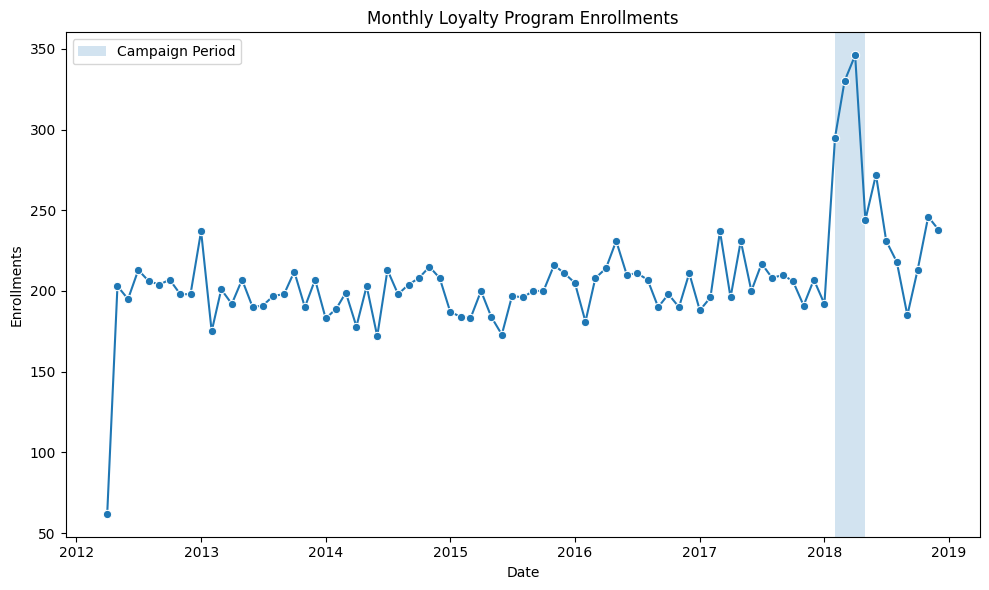

In [164]:
#monthy enrollment chart:

monthly_enrollments = (final_customer_data.groupby(pd.Grouper(key='enrollment_date',freq='MS')).size().reset_index(name='enrollments'))

monthly_enrollments = monthly_enrollments.sort_values('enrollment_date')

plt.figure(figsize=(10,6))

sns.lineplot(data=monthly_enrollments, x='enrollment_date', y='enrollments', marker='o')

plt.axvspan(pd.Timestamp('2018-02-01'), pd.Timestamp('2018-04-30'), alpha=0.2, label='Campaign Period')

plt.title('Monthly Loyalty Program Enrollments')
plt.xlabel('Date')
plt.ylabel('Enrollments')

plt.legend()
plt.tight_layout()
plt.show()

- The 2018 promotional campaign coincided with a substantial increase in loyalty program enrollments,

 with monthly sign-ups rising from the historical average of approximately 200 customers per month to over 340 during the campaign period.

#### section-2: campaign performance

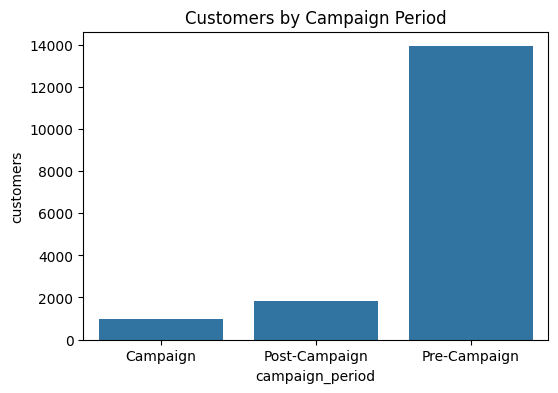

In [149]:
#COMPARISON BY CAMPAIGN PERIOD 

campaign_summary = (final_customer_data.groupby('campaign_period').agg(customers=('loyalty_number','count')).reset_index())

plt.figure(figsize=(6,4))
sns.barplot(data=campaign_summary, x='campaign_period',y='customers')

plt.title('Customers by Campaign Period')
plt.show()

- most customers were acquired before the campaign. (after campaign time-frame in dataset is short)

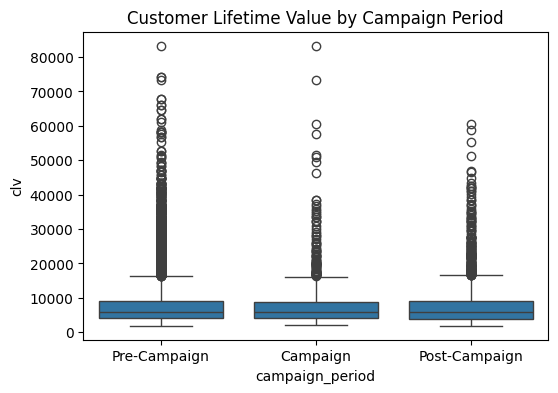

In [150]:
#CLV BY CAMPAIGN PERIOD

plt.figure(figsize=(6,4))

sns.boxplot(data=final_customer_data, x='campaign_period',y='clv')

plt.title('Customer Lifetime Value by Campaign Period')
plt.show()

- median CLV is very similar hence, campaign customers do not appear less valuable than non-campaign customers.

#### SECTION-3: retention analysis

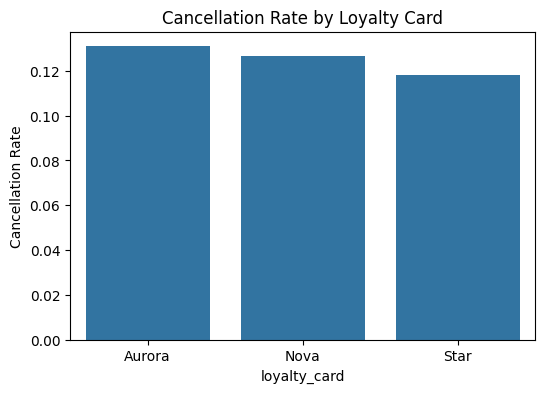

In [151]:
#CHURN RATE BY LOYALTY CARD 
churn_card = (final_customer_data.groupby('loyalty_card')['is_cancelled'].mean().sort_values(ascending=False).reset_index())

plt.figure(figsize=(6,4))

sns.barplot(data=churn_card, x='loyalty_card',y='is_cancelled')

plt.title('Cancellation Rate by Loyalty Card')
plt.ylabel('Cancellation Rate')
plt.show()

- Loyalty tier does not appear to strongly influence cancellation behavior.

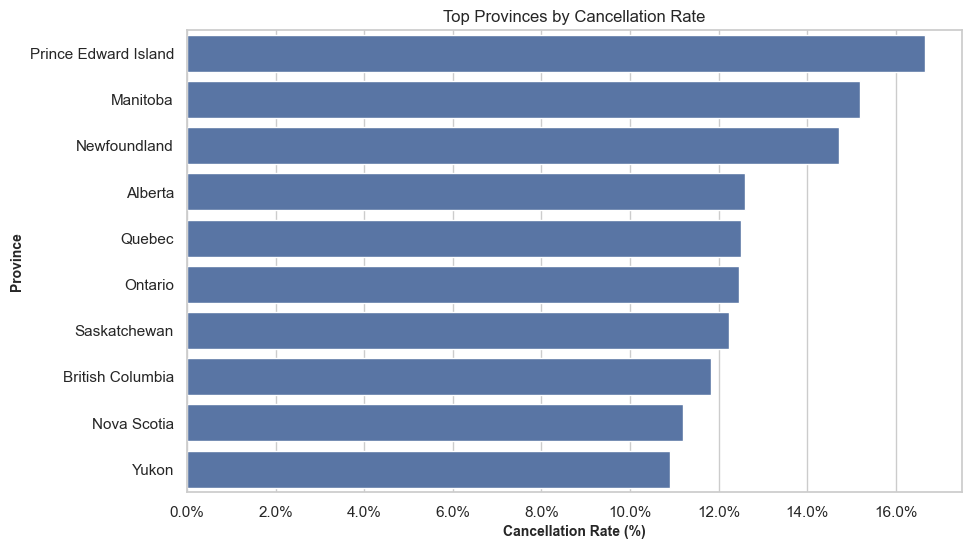

In [171]:
#PROVINCE VS CHURN RATE
import matplotlib.ticker as mtick
province_churn = (final_customer_data.groupby('province')['is_cancelled'].mean().sort_values(ascending=False).head(10).reset_index())

plt.figure(figsize=(10,6))

ax= sns.barplot(data=province_churn, x='is_cancelled', y='province')
plt.xlabel("Cancellation Rate (%)", fontsize=10, fontweight='bold')
plt.ylabel("Province", fontsize=10, fontweight='bold')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.title('Top Provinces by Cancellation Rate')
plt.show()

#### section-4: customer-value analysis

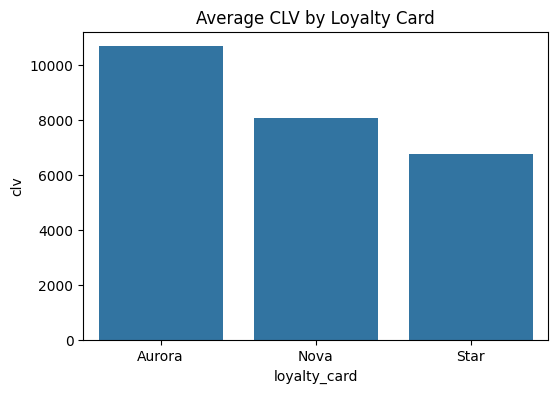

In [153]:
#AVG. CLV BY LOYALTY CARD

clv_card = (final_customer_data.groupby('loyalty_card')['clv'].mean().sort_values(ascending=False).reset_index())

plt.figure(figsize=(6,4))

sns.barplot(data=clv_card, x='loyalty_card', y='clv')
plt.title('Average CLV by Loyalty Card')
plt.show()

- Aurora customers generate significantly higher lifetime value.

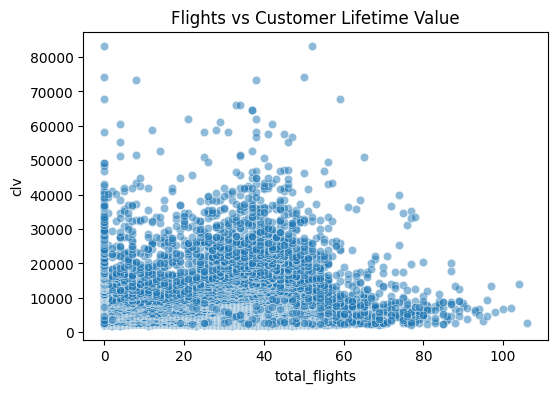

In [154]:
#FLIGHTS VS CLV:

plt.figure(figsize=(6,4))
sns.scatterplot(data=final_customer_data, x='total_flights', y='clv', alpha=0.5)

plt.title('Flights vs Customer Lifetime Value')
plt.show()

- no obvious positive trend
- flight frequency alone is not a reliable indicator of customer lifetime value.

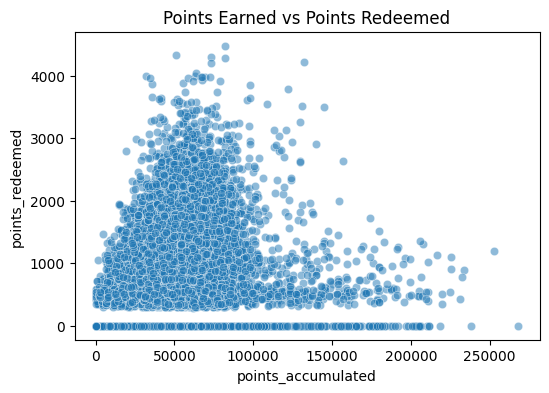

In [155]:
#POINTS EARNED VS REDEEMED

plt.figure(figsize=(6,4))

sns.scatterplot(data=final_customer_data, x='points_accumulated', y='points_redeemed', alpha=0.5)
plt.title('Points Earned vs Points Redeemed')
plt.show()

- many customers accumulate points but redeem less.

#### section-5: customer-segmentation

In [156]:
#segmentation:
condition = [((final_customer_data['clv_buckets']=='High') & (final_customer_data['avg_flights_per_active_month'] >= 2)),
    ((final_customer_data['clv_buckets']=='High')),  
    (final_customer_data['avg_flights_per_active_month'] >= 1)]

segments = ['High Value - Frequent Flyers',
    'High Value - Occasional Flyers',
    'Moderate - Active Members']

final_customer_data['segment'] = np.select(condition, segments, default='Low Engagement Members'
)

In [157]:
final_customer_data[['loyalty_number', 'segment']].head()

,loyalty_number,segment
0,480934,Moderate - Active Members
1,549612,Moderate - Active Members
2,429460,Moderate - Active Members
3,608370,Moderate - Active Members
4,530508,Moderate - Active Members


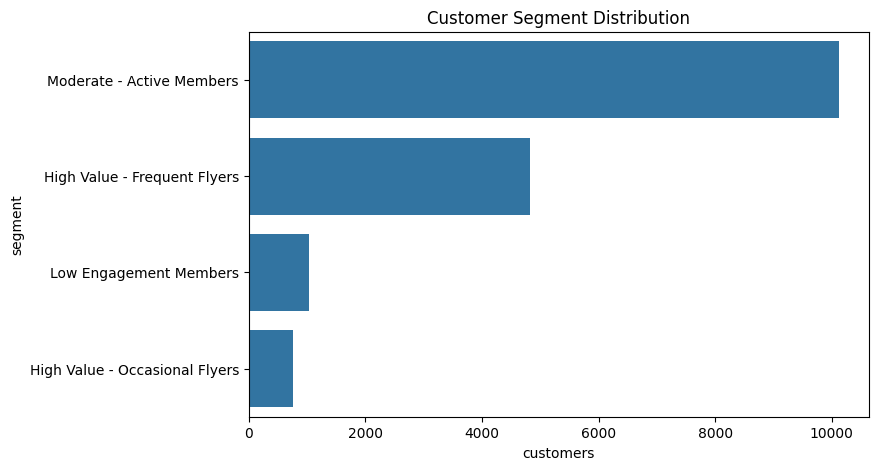

In [158]:
# segment-distribution chart:
segment_counts = (final_customer_data['segment'].value_counts().reset_index())
segment_counts.columns = ['segment','customers']

plt.figure(figsize=(8,5))

sns.barplot(data=segment_counts, x='customers', y='segment')
plt.title('Customer Segment Distribution')
plt.show()

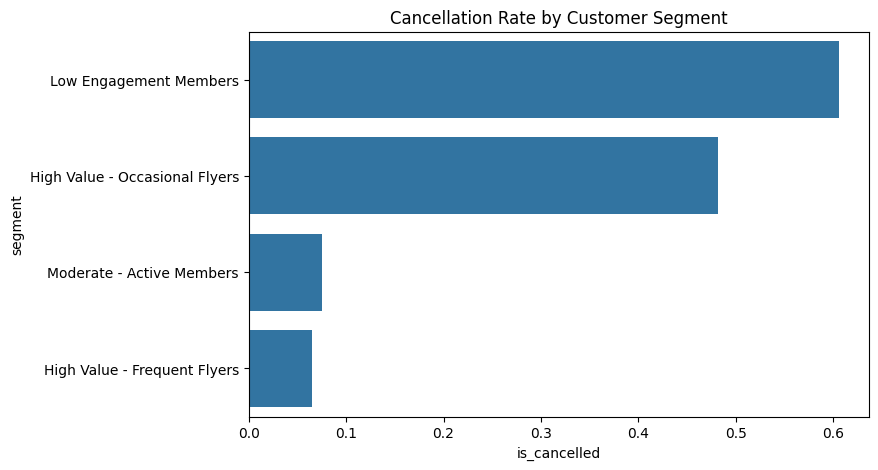

In [159]:
#SEGMENT-WISE CHURN RATE:

segment_churn = (final_customer_data.groupby('segment')['is_cancelled'].mean().sort_values(ascending=False).reset_index())

plt.figure(figsize=(8,5))

sns.barplot(data=segment_churn, x='is_cancelled', y='segment')
plt.title('Cancellation Rate by Customer Segment')
plt.show()

### SUMMARY:

## Key Insights

1. The 2018 Campaign Successfully Increased Customer Acquisition

Monthly enrollments remained relatively stable between 2012 and 2017. During the February–April 2018 campaign period, enrollments increased significantly, peaking at over 340 enrollments in a single month.

2. Campaign-Acquired Customers Maintained Comparable Value

Customer Lifetime Value (CLV) distributions were similar across pre-campaign, campaign, and post-campaign customer groups, suggesting that the campaign increased acquisition volume without significantly reducing customer quality.

3. Customer Retention Varies by Region

Cancellation rates differed across provinces, indicating geographic differences in customer retention behavior.

4. Loyalty Tier Impacts Customer Value More Than Retention

Aurora members generated the highest average CLV, while cancellation rates remained relatively similar across loyalty card tiers.

5. Flight Activity Alone Does Not Determine Customer Value

Flight frequency showed some relationship with CLV, but customer value was influenced by multiple behavioral factors.

6. Many Customers Accumulate More Points Than They Redeem

A large portion of members accumulated substantial point balances while redeeming relatively few rewards, suggesting opportunities to improve loyalty engagement.

## Business Recommendations

- Continue targeted acquisition campaigns similar to the 2018 promotion.
- Focus retention efforts on provinces with elevated cancellation rates.
- Increase reward redemption through personalized offers and reminder campaigns.
- Prioritize retention of high-value Aurora members.
- Expand future analysis using additional behavioral variables such as booking frequency, route preferences, and redemption patterns.

## SUMMARY CHART:

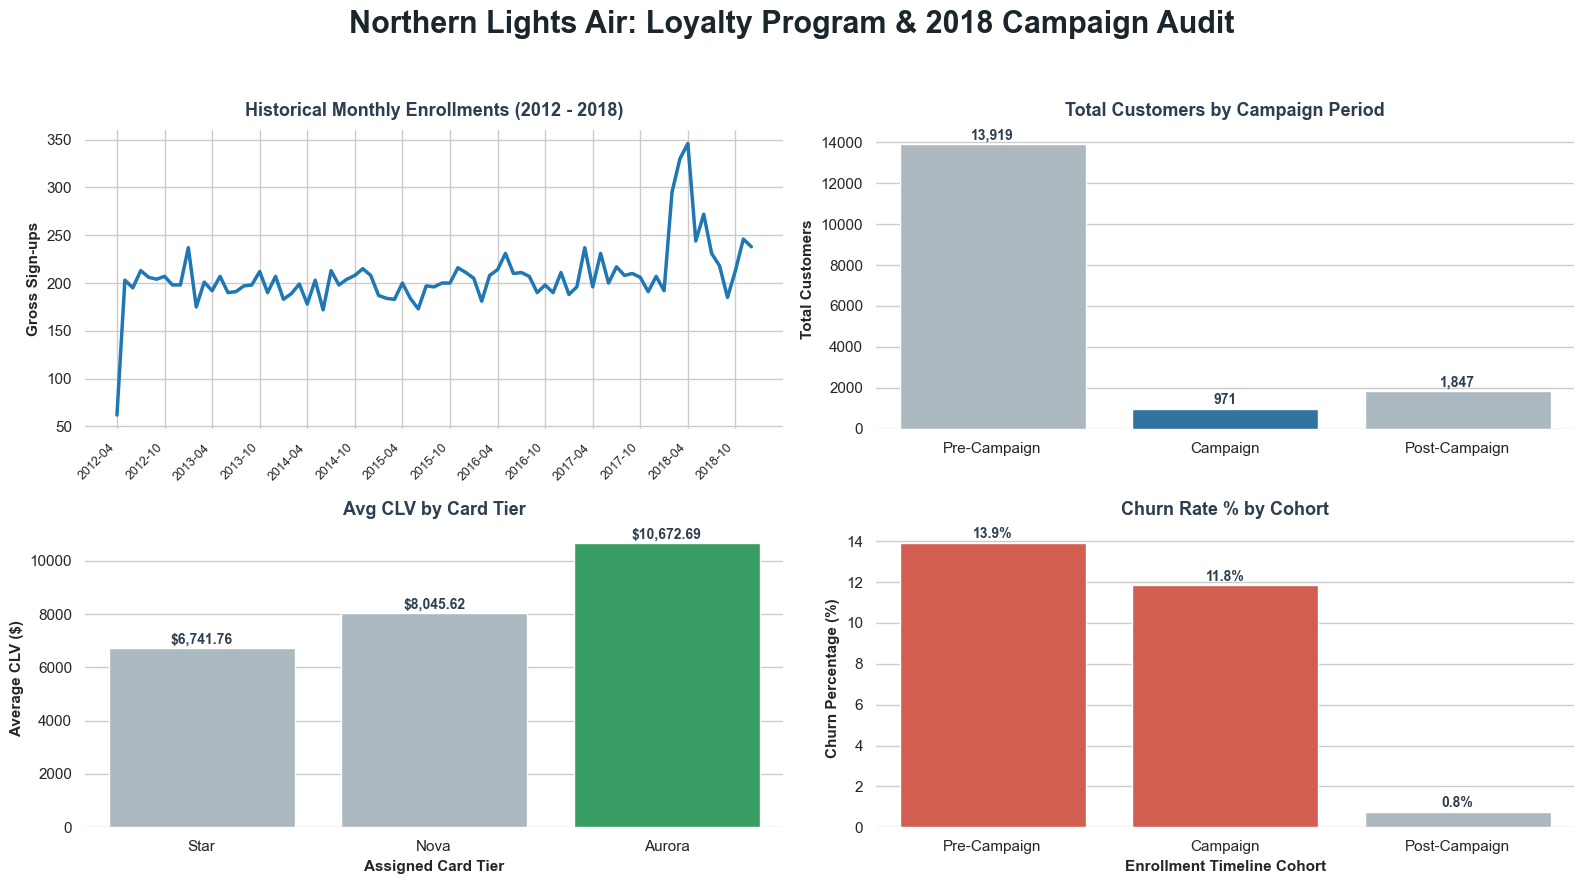

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#DATA PREPARATION
#Load engineered dataset
df = pd.read_csv("final_customer_data.csv")
df['enrollment_date'] = pd.to_datetime(df['enrollment_date'])

#Plot 1: Monthly Trend
trend_df = df.groupby(df['enrollment_date'].dt.to_period('M')).size().reset_index(name='Enrollments')
trend_df['enrollment_date'] = trend_df['enrollment_date'].astype(str)

#Plot 2: Campaign Cohort
campaign_df = df.groupby('campaign_period').size().reset_index(name='Customers')

#Plot 3:Avg CLV
clv_df = df.groupby('loyalty_card')['clv'].mean().reset_index()

#Plot 4: Retention(Churn rate %)
churn_df = df.groupby('campaign_period').agg(
    total=('is_cancelled', 'count'),
    cancelled=('is_cancelled', 'sum')
).reset_index()
churn_df['churn_rate'] = (churn_df['cancelled'] / churn_df['total']) * 100



sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
fig.suptitle("Northern Lights Air: Loyalty Program & 2018 Campaign Audit", 
             fontsize=22, fontweight='bold', color='#1A252C', y=0.98)

#Palette 
primary_blue = '#1F77B4'
neutral_grey = '#A8BAC4'
dark_slate = '#2C3E50'
alert_coral = '#E74C3C'


#PLOT-1
ax1 = axes[0, 0]
sns.lineplot(data=trend_df, x='enrollment_date', y='Enrollments', ax=ax1, color=primary_blue, linewidth=2.5)

#Style
ax1.set_title("Historical Monthly Enrollments (2012 - 2018)", fontsize=13, fontweight='bold', color=dark_slate, pad=10)
ax1.set_xlabel("", fontsize=10)
ax1.set_ylabel("Gross Sign-ups", fontsize=11, fontweight='bold')

#Reduce clutter(Show every 6th month)
ax1.set_xticks(trend_df['enrollment_date'][::6])
ax1.set_xticklabels(trend_df['enrollment_date'][::6], rotation=45, ha='right', fontsize=9)


#PLOT 2
ax2 = axes[0, 1]
sns.barplot(
    data=campaign_df, x='campaign_period', y='Customers', ax=ax2,
    palette=[neutral_grey, primary_blue, neutral_grey],
    order=['Pre-Campaign', 'Campaign', 'Post-Campaign']
)
ax2.set_title("Total Customers by Campaign Period", fontsize=13, fontweight='bold', color=dark_slate, pad=10)
ax2.set_xlabel("", fontsize=10)
ax2.set_ylabel("Total Customers", fontsize=11, fontweight='bold')

#numeric data tags
for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 6), textcoords='offset points', 
                 fontsize=10, fontweight='bold', color=dark_slate)


#PLOT-3
ax3 = axes[1, 0]
sns.barplot(
    data=clv_df, x='loyalty_card', y='clv', ax=ax3,
    palette=[neutral_grey, neutral_grey, '#27AE60'], #Distinct color highlighting top tier
    order=['Star', 'Nova', 'Aurora']
)
ax3.set_title("Avg CLV by Card Tier", fontsize=13, fontweight='bold', color=dark_slate, pad=10)
ax3.set_xlabel("Assigned Card Tier", fontsize=11, fontweight='bold')
ax3.set_ylabel("Average CLV ($)", fontsize=11, fontweight='bold')

#tags
for p in ax3.patches:
    ax3.annotate(f'${p.get_height():,.2f}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 6), textcoords='offset points', 
                 fontsize=10, fontweight='bold', color=dark_slate)

#PLOT4:
ax4 = axes[1, 1]
sns.barplot(
    data=churn_df, x='campaign_period', y='churn_rate', ax=ax4,
    palette=[alert_coral, alert_coral, neutral_grey], 
    order=['Pre-Campaign', 'Campaign', 'Post-Campaign']
)
ax4.set_title("Churn Rate % by Cohort", fontsize=13, fontweight='bold', color=dark_slate, pad=10)
ax4.set_xlabel("Enrollment Timeline Cohort", fontsize=11, fontweight='bold')
ax4.set_ylabel("Churn Percentage (%)", fontsize=11, fontweight='bold')

#Percentage marks
for p in ax4.patches:
    ax4.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 6), textcoords='offset points', 
                 fontsize=10, fontweight='bold', color=dark_slate)

#CLEANUP & DISPLAY
sns.despine(left=True, bottom=True)
plt.tight_layout(rect=[0, 0, 1, 0.95]) #Prevent title overlap

plt.show()